In [12]:

import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# Folder containing the data files
folder = Path("Velocity files for FSI")

# Dictionary to store all datasets
data = {}

# Loop through every .dat file
for file in sorted(folder.glob("*.dat")):
    data[file.stem] = np.loadtxt(file)

print(f"Loaded {len(data)} datasets")


Loaded 14 datasets


In [13]:
means = {}
fluctuations = {}
stds = {}

Uref = 1.5

for name, array in data.items():
    velocity = array[:,1:3]
    means[name] = np.mean(array[:, 1:3], axis=0)
    fluctuations[name] = velocity - means[name]
    stds[name] = np.std(array[:, 1:3], axis=0)

    #print(f"{name}:")
    #print(f"  Mean u, v: {means[name]}")
    #print(f"  Std u, v:  {stds[name]}")

rho = 1020 #kg/m^3

reynolds_stresses = {}

for name, fluct in fluctuations.items():

    u_prime = fluct[:, 0]
    v_prime = fluct[:, 1]

    # Average products of fluctuations u*v
    tau = -np.mean(u_prime * v_prime)


    reynolds_stresses[name] = tau

    print(f"{name}:")
    print(tau)

Z_02.7:
0.003191024871092804
Z_07.3:
0.005426515286449257
Z_10.6:
0.005557803937117266
Z_16.8:
0.005607739928061798
Z_23.3:
0.005058964768578485
Z_29.7:
0.004803278158470332
Z_36.0:
0.004005019611487204
Z_42.4:
0.0038669932896548604
Z_48.8:
0.0032046885836495417
Z_55.3:
0.0024707838667389426
Z_61.5:
0.0016542249261688893
Z_74.4:
0.000997811604853992
Z_87.0:
0.00038264872434090087
Z_94.4:
0.00013825877259884798


[ 0.00647834 -0.00698616]
[[1.    0.073]
 [1.    0.106]
 [1.    0.168]
 [1.    0.233]
 [1.    0.297]
 [1.    0.36 ]
 [1.    0.424]
 [1.    0.488]
 [1.    0.553]
 [1.    0.615]
 [1.    0.744]
 [1.    0.87 ]
 [1.    0.944]]


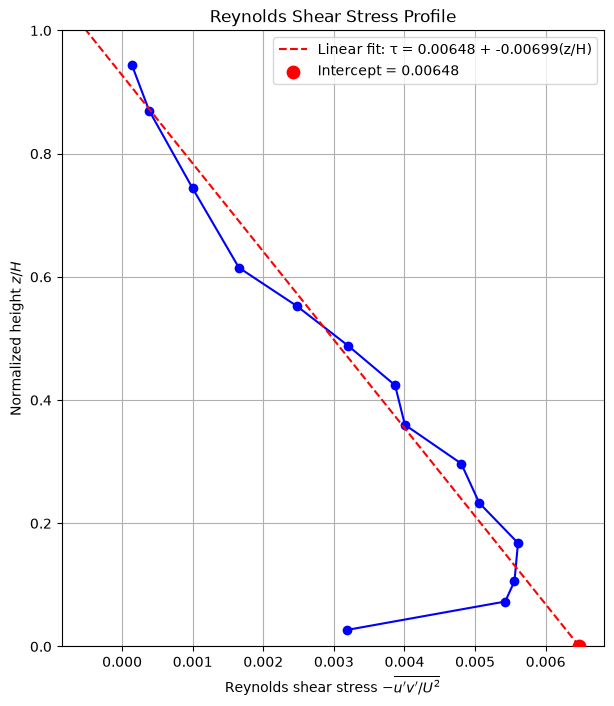

In [34]:
heights = []
tau_values = []

for name, tau in reynolds_stresses.items():

    # Extract height from filename
    height = float(name.split("_")[1]) / 100

    heights.append(height)
    tau_values.append(tau)

# Convert to NumPy arrays
heights = np.array(heights)
tau_values = np.array(tau_values)

# Sort values by height
order = np.argsort(heights)

heights = heights[order]
tau_values = tau_values[order]

A1 = np.ones(13)
A2 = heights[1:]

A = np.column_stack((A1, A2))

X_hat = np.linalg.inv(A.T @ A) @ A.T @ tau_values[1:]

B1 = np.ones(14)
B2 = heights
B = np.column_stack((B1, B2))

K_hat = np.linalg.inv(B.T @ B) @ B.T @ tau_values

print(X_hat)
print(A)
# Plot Reynolds shear stress vs height
plt.figure(figsize=(7, 8))

plt.plot(tau_values, heights, 'o-', color='blue')

plt.xlabel(r"Reynolds shear stress $-\overline{u'v'/U^2}$")

# Generate heights for the fitted line
z_fit = np.linspace(0, 1, 100)

# Calculate fitted Reynolds shear stress
tau_fit = X_hat[0] + X_hat[1] * z_fit

# Plot the fitted line
plt.plot(tau_fit, z_fit, 'r--',
         label=f'Linear fit: τ = {X_hat[0]:.5f} + {X_hat[1]:.5f}(z/H)')

# Mark the intercept at z/H = 0
plt.scatter(X_hat[0], 0, color='red', s=80,
            label=f'Intercept = {X_hat[0]:.5f}', zorder=5)

plt.legend()

plt.ylabel(r"Normalized height $z/H$")
plt.title("Reynolds Shear Stress Profile")

plt.ylim(0, 1)
plt.grid(True)
plt.show()


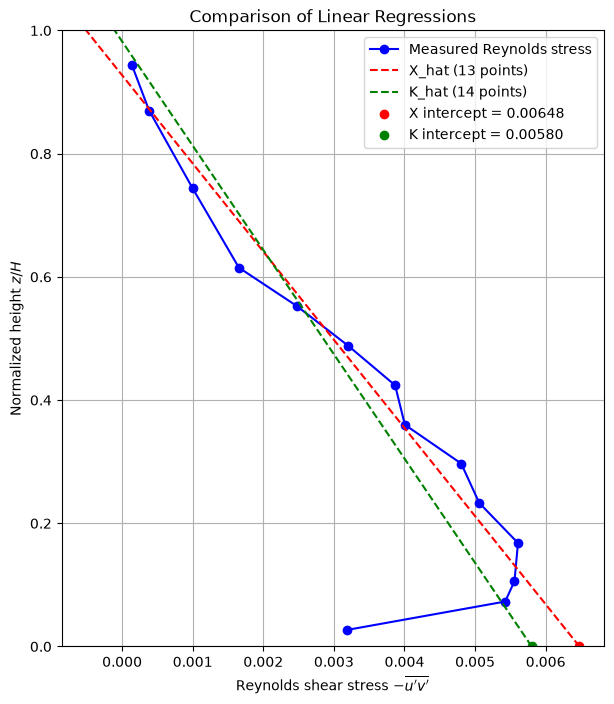

In [35]:

# Generate heights for the fitted lines
z_fit = np.linspace(0, 1, 100)

# Calculate both regression lines
tau_X = X_hat[0] + X_hat[1] * z_fit
tau_K = K_hat[0] + K_hat[1] * z_fit

plt.figure(figsize=(7, 8))

# Original data
plt.plot(tau_values, heights, 'o-', color='blue',
         label='Measured Reynolds stress')

# Regression excluding last point
plt.plot(tau_X, z_fit, 'r--',
         label='X_hat (13 points)')

# Regression using all points
plt.plot(tau_K, z_fit, 'g--',
         label='K_hat (14 points)')

# Mark both intercepts
plt.scatter(X_hat[0], 0, color='red',
            label=f'X intercept = {X_hat[0]:.5f}')

plt.scatter(K_hat[0], 0, color='green',
            label=f'K intercept = {K_hat[0]:.5f}')

plt.xlabel(r"Reynolds shear stress $-\overline{u'v'}$")
plt.ylabel(r"Normalized height $z/H$")
plt.title("Comparison of Linear Regressions")

plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()
